In [28]:
# imports
import pandas as pd

In [29]:
# import Data
weather_df = pd.read_csv('../data/weather_burbank_airport.csv')
charging_df = pd.read_csv('../data/charging_sessions.csv')

charging_df.describe()
charging_df.info()
charging_df.head()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 66450 entries, 0 to 66449
Data columns (total 13 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Unnamed: 0        66450 non-null  int64  
 1   id                66450 non-null  object 
 2   connectionTime    66450 non-null  object 
 3   disconnectTime    66450 non-null  object 
 4   doneChargingTime  62362 non-null  object 
 5   kWhDelivered      66450 non-null  float64
 6   sessionID         66450 non-null  object 
 7   siteID            66450 non-null  int64  
 8   spaceID           66450 non-null  object 
 9   stationID         66450 non-null  object 
 10  timezone          66450 non-null  object 
 11  userID            49187 non-null  float64
 12  userInputs        49187 non-null  object 
dtypes: float64(2), int64(2), object(9)
memory usage: 6.6+ MB


,Unnamed: 0,id,connectionTime,disconnectTime,doneChargingTime,kWhDelivered,sessionID,siteID,spaceID,stationID,timezone,userID,userInputs
0,0,5e23b149f9af8b5fe4b973cf,2020-01-02 13:08:54+00:00,2020-01-02 19:11:15+00:00,2020-01-02 17:31:35+00:00,25.016,1_1_179_810_2020-01-02 13:08:53.870034,1,AG-3F30,1-1-179-810,America/Los_Angeles,194.0,"[{'WhPerMile': 250, 'kWhRequested': 25.0, 'mil..."
1,1,5e23b149f9af8b5fe4b973d0,2020-01-02 13:36:50+00:00,2020-01-02 22:38:21+00:00,2020-01-02 20:18:05+00:00,33.097,1_1_193_825_2020-01-02 13:36:49.599853,1,AG-1F01,1-1-193-825,America/Los_Angeles,4275.0,"[{'WhPerMile': 280, 'kWhRequested': 70.0, 'mil..."
2,2,5e23b149f9af8b5fe4b973d1,2020-01-02 13:56:35+00:00,2020-01-03 00:39:22+00:00,2020-01-02 16:35:06+00:00,6.521,1_1_193_829_2020-01-02 13:56:35.214993,1,AG-1F03,1-1-193-829,America/Los_Angeles,344.0,"[{'WhPerMile': 400, 'kWhRequested': 8.0, 'mile..."
3,3,5e23b149f9af8b5fe4b973d2,2020-01-02 13:59:58+00:00,2020-01-02 16:38:39+00:00,2020-01-02 15:18:45+00:00,2.355,1_1_193_820_2020-01-02 13:59:58.309319,1,AG-1F04,1-1-193-820,America/Los_Angeles,1117.0,"[{'WhPerMile': 400, 'kWhRequested': 8.0, 'mile..."
4,4,5e23b149f9af8b5fe4b973d3,2020-01-02 14:00:01+00:00,2020-01-02 22:08:40+00:00,2020-01-02 18:17:30+00:00,13.375,1_1_193_819_2020-01-02 14:00:00.779967,1,AG-1F06,1-1-193-819,America/Los_Angeles,334.0,"[{'WhPerMile': 400, 'kWhRequested': 16.0, 'mil..."


In [30]:
# check null values for both datasets
# Count NaN values in each column
nan_counts = charging_df.isna().sum()
print("NaN count per column:\n", nan_counts)
print("\n")
print("Percentage of NaN values: \ndoneChargingTime: ", nan_counts['doneChargingTime'] / len(charging_df) * 100)
print("userID: ", nan_counts['userID'] / len(charging_df) * 100)
print("userInputs: ", nan_counts['userInputs'] / len(charging_df) * 100)
print("\n")


# for weather dataset
nan_counts_weather = weather_df.isna().sum()
print("NaN count per column:\n", nan_counts_weather)
print("\n")
print("temperature: ", nan_counts_weather['temperature'] / len(weather_df) * 100)
print("cloud_cover: ", nan_counts_weather['cloud_cover'] / len(weather_df) * 100)
print("cloud_cover_description: ", nan_counts_weather['cloud_cover_description'] / len(weather_df) * 100)
print("windspeed: ", nan_counts_weather['windspeed'] / len(weather_df) * 100)
print("felt_temperature: ", nan_counts_weather['felt_temperature'] / len(weather_df) * 100)

NaN count per column:
 Unnamed: 0              0
id                      0
connectionTime          0
disconnectTime          0
doneChargingTime     4088
kWhDelivered            0
sessionID               0
siteID                  0
spaceID                 0
stationID               0
timezone                0
userID              17263
userInputs          17263
dtype: int64


Percentage of NaN values: 
doneChargingTime:  6.151993980436418
userID:  25.978931527464262
userInputs:  25.978931527464262


NaN count per column:
 city                        0
timestamp                   0
temperature                25
cloud_cover                20
cloud_cover_description    20
pressure                    8
windspeed                  86
precipitation               0
felt_temperature           26
dtype: int64


temperature:  0.08548762139242237
cloud_cover:  0.0683900971139379
cloud_cover_description:  0.0683900971139379
windspeed:  0.294077417589933
felt_temperature:  0.08890712624811928


No columns with very high NaN percentages, so drop no column

In [31]:
# use one of space id, station id, or site id, since they are dependent
# drop site id
charging_df = charging_df.drop(columns=['siteID'])
#drop sessionid, contains information that is in the other columns
charging_df = charging_df.drop(columns=['sessionID'])
# is the a entry where timezone is not los angeles?
charging_df.groupby('timezone').count()
# since the value is always los angeles and there are no missing values, we can drop the column
charging_df = charging_df.drop(columns=['timezone'])
# drop unnamed column
charging_df = charging_df.drop(columns=['Unnamed: 0'])
# drop id column
charging_df = charging_df.drop(columns=['id'])

charging_df.head(20)

,connectionTime,disconnectTime,doneChargingTime,kWhDelivered,spaceID,stationID,userID,userInputs
0,2020-01-02 13:08:54+00:00,2020-01-02 19:11:15+00:00,2020-01-02 17:31:35+00:00,25.016,AG-3F30,1-1-179-810,194.0,"[{'WhPerMile': 250, 'kWhRequested': 25.0, 'mil..."
1,2020-01-02 13:36:50+00:00,2020-01-02 22:38:21+00:00,2020-01-02 20:18:05+00:00,33.097,AG-1F01,1-1-193-825,4275.0,"[{'WhPerMile': 280, 'kWhRequested': 70.0, 'mil..."
2,2020-01-02 13:56:35+00:00,2020-01-03 00:39:22+00:00,2020-01-02 16:35:06+00:00,6.521,AG-1F03,1-1-193-829,344.0,"[{'WhPerMile': 400, 'kWhRequested': 8.0, 'mile..."
3,2020-01-02 13:59:58+00:00,2020-01-02 16:38:39+00:00,2020-01-02 15:18:45+00:00,2.355,AG-1F04,1-1-193-820,1117.0,"[{'WhPerMile': 400, 'kWhRequested': 8.0, 'mile..."
4,2020-01-02 14:00:01+00:00,2020-01-02 22:08:40+00:00,2020-01-02 18:17:30+00:00,13.375,AG-1F06,1-1-193-819,334.0,"[{'WhPerMile': 400, 'kWhRequested': 16.0, 'mil..."
5,2020-01-02 14:00:13+00:00,2020-01-02 23:00:41+00:00,2020-01-02 20:13:21+00:00,13.370,AG-1F13,1-1-194-821,3519.0,"[{'WhPerMile': 600, 'kWhRequested': 24.0, 'mil..."
6,2020-01-02 14:09:14+00:00,2020-01-03 01:57:58+00:00,2020-01-03 00:59:21+00:00,43.477,AG-1F09,1-1-178-817,933.0,"[{'WhPerMile': 385, 'kWhRequested': 65.45, 'mi..."
7,2020-01-02 14:17:32+00:00,2020-01-03 00:44:54+00:00,2020-01-02 20:22:40+00:00,32.441,AG-4F34,1-1-191-804,3737.0,"[{'WhPerMile': 300, 'kWhRequested': 45.0, 'mil..."
8,2020-01-02 14:25:38+00:00,2020-01-02 19:36:05+00:00,2020-01-02 18:38:39+00:00,13.264,AG-1F11,1-1-194-826,419.0,"[{'WhPerMile': 400, 'kWhRequested': 40.0, 'mil..."
9,2020-01-02 14:27:40+00:00,2020-01-02 20:01:48+00:00,2020-01-02 19:17:46+00:00,13.285,AG-1F08,1-1-178-823,651.0,"[{'WhPerMile': 400, 'kWhRequested': 20.0, 'mil..."


User Input must be transformed to be used in the analysis

Put into own columns each

Interesting information, WhPerMile, kWhRequested, milesrequested, minutesAvailable

userID is already in the dataset, as well as modifiedAt, paymentrequired is always true

In [32]:
# [{'WhPerMile': 250, 'kWhRequested': 25.0, 'milesRequested': 100, 'minutesAvailable': 463, 'modifiedAt': 'Thu, 02 Jan 2020 13:09:39 GMT', 'paymentRequired': True, 'requestedDeparture': 'Thu, 02 Jan 2020 20:51:54 GMT', 'userID': 194}]

import ast

kwhPerMile = []
kwhRequested = []
milesRequested = []
minutesAvailable = []

userinput = charging_df['userInputs']
userinput
for row in userinput:
    dicts = []
    if pd.notna(row):
        parsed = ast.literal_eval(row)
        if parsed:
            dicts.append(parsed[0]) # only add the first dict if theres multiple as it would get too complex elsewise

        for d in dicts:
            for key, value in d.items():
                kwhPerMile.append(value) if key == 'WhPerMile' else None
                kwhRequested.append(value) if key == 'kWhRequested' else None
                milesRequested.append(value) if key == 'milesRequested' else None
                minutesAvailable.append(value) if key == 'minutesAvailable' else None

charging_df['kWhPerMile'] = kwhPerMile
charging_df['kWhRequested'] = kwhRequested
charging_df['milesRequested'] = milesRequested
charging_df['minutesAvailable'] = minutesAvailable

charging_df = charging_df.drop(columns=['userInputs'])

ValueError: Length of values (49187) does not match length of index (66450)

In [33]:
weather_df.head(20)

# drop city as its always burbank
weather_df = weather_df.drop(columns=['city'])

# convert cloud_cover_description to categorical
weather_df.groupby('cloud_cover_description').count()

cloud_cover_dummies = pd.get_dummies(weather_df['cloud_cover_description']).astype(int)

weather_df.join(cloud_cover_dummies).drop(columns=['cloud_cover_description']).head(20)

,timestamp,temperature,cloud_cover,pressure,windspeed,precipitation,felt_temperature,Blowing Dust,Cloudy,Cloudy / Windy,...,Mostly Cloudy,Mostly Cloudy / Windy,Partly Cloudy,Partly Cloudy / Windy,Rain,Rain / Windy,Smoke,T-Storm,Thunder,Thunder in the Vicinity
0,2018-01-01 08:53:00,9.0,33.0,991.75,9.0,0.0,8.0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,2018-01-01 09:53:00,9.0,33.0,992.08,0.0,0.0,9.0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,2018-01-01 10:53:00,9.0,21.0,992.08,0.0,0.0,9.0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
3,2018-01-01 11:53:00,9.0,29.0,992.08,0.0,0.0,9.0,0,0,0,...,0,0,1,0,0,0,0,0,0,0
4,2018-01-01 12:53:00,8.0,33.0,992.08,0.0,0.0,8.0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
5,2018-01-01 13:53:00,8.0,33.0,992.08,0.0,0.0,8.0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
6,2018-01-01 14:53:00,7.0,30.0,992.08,0.0,0.0,7.0,0,0,0,...,0,0,1,0,0,0,0,0,0,0
7,2018-01-01 15:53:00,8.0,34.0,992.41,0.0,0.0,8.0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
8,2018-01-01 16:53:00,12.0,34.0,993.39,0.0,0.0,12.0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
9,2018-01-01 17:53:00,16.0,34.0,994.05,0.0,0.0,16.0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


Boxplots for each column

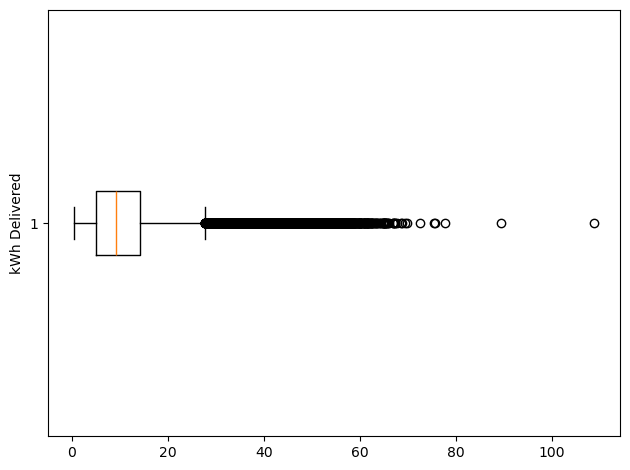

In [34]:
import matplotlib.pyplot as plt
fig, ax = plt.subplots()

ax.boxplot(charging_df['kWhDelivered'], vert=False)
ax.set_ylabel('kWh Delivered')
plt.tight_layout()
plt.show()

timestamp                   object
temperature                float64
cloud_cover                float64
cloud_cover_description     object
pressure                   float64
windspeed                  float64
precipitation              float64
felt_temperature           float64
dtype: object
                    count  nunique    min  median     max
temperature       29219.0     45.0    2.0   17.00   46.00
cloud_cover       29224.0     17.0    4.0   33.00   47.00
pressure          29236.0     88.0  971.0  986.48  999.65
windspeed         29158.0     28.0    0.0    7.00   57.00
precipitation     29244.0     44.0    0.0    0.00   18.54
felt_temperature  29218.0     43.0    0.0   17.00   42.00


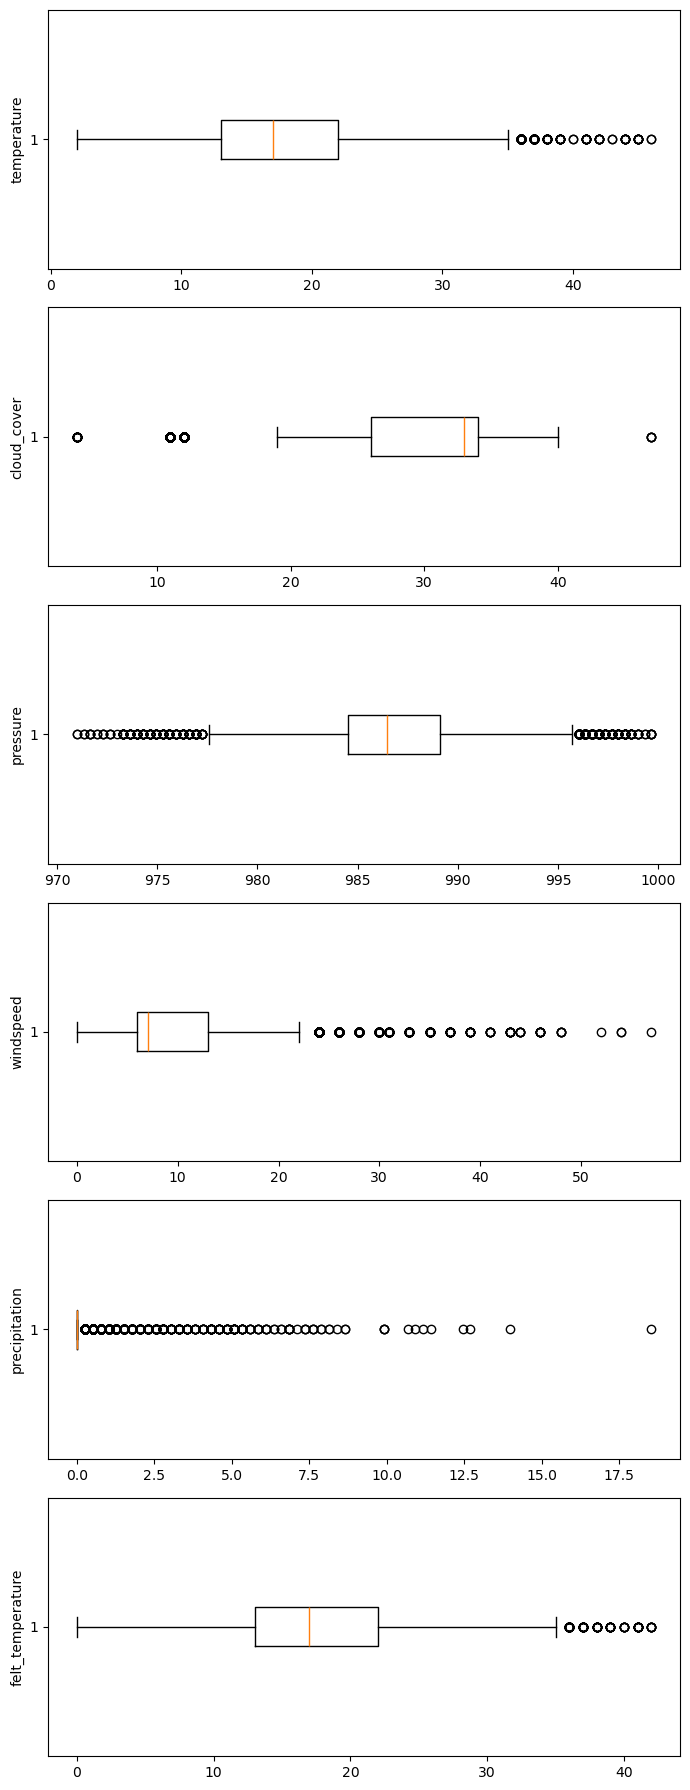

In [ ]:
print(weather_df.dtypes)

numeric_cols = weather_df.select_dtypes(include="number").columns

print(
    weather_df[numeric_cols]
    .agg(["count", "nunique", "min", "median", "max"])
    .T
)

fig, axs = plt.subplots(len(numeric_cols), 1, figsize=(7, 3 * len(numeric_cols)), squeeze=False)

for ax, col in zip(axs[:, 0], numeric_cols):
    ax.boxplot(weather_df[col].dropna(), vert=False)
    ax.set_ylabel(col)

plt.tight_layout()
plt.show()

Correlation Analysis

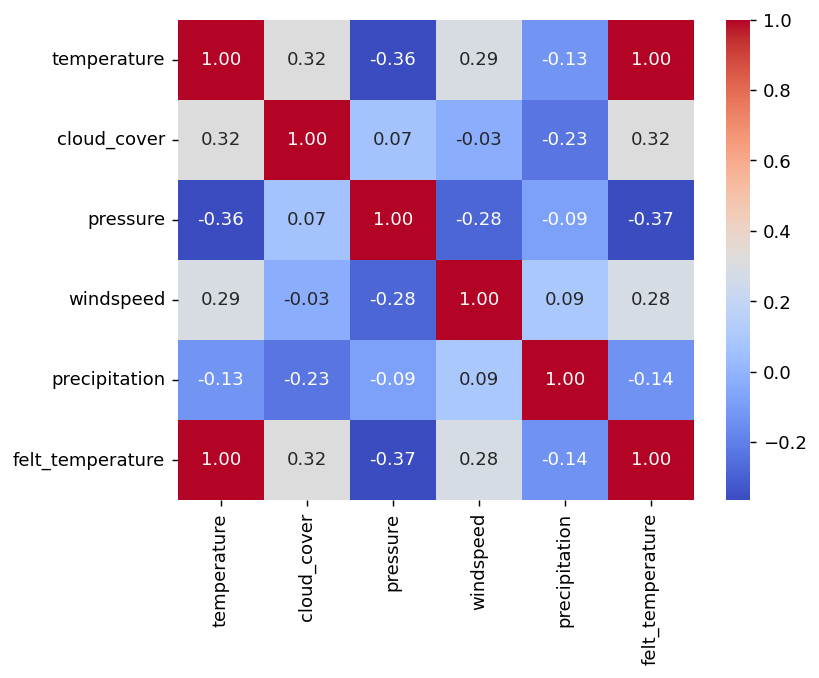

In [ ]:
import seaborn as sns

num_df = weather_df.select_dtypes(include=['float64', 'int64'])

corr = num_df.corr()
plt.figure(dpi=130)
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm')
plt.show()